# Actividad 5 (20 %): Experimentos con diferentes tamaños

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

Se ejecuta el algoritmo de Grover modular (actividades 3 y 4) para $n = 4$, $n = 5$ y $n = 6$ con un estado marcado, y un caso adicional
con dos estados marcados ($n = 5$). Para cada experimento se reporta:

- Número de qubits y tamaño del espacio de búsqueda $N = 2^n$.
- Estado o estados marcados.
- Número de iteraciones calculado con `Iteraciones(n, M)`.
- Distribución de probabilidades final (exacta, con `Statevector`).
- Probabilidad de éxito: **suma** de las probabilidades de todos los estados marcados.
- Resultados de la medición (`AerSimulator`, 1024 disparos).

Los resultados se guardan en `../resultados/` y los histogramas en `../figuras/`.

In [ ]:
!pip install qiskit qiskit-aer

In [ ]:
!pip install -q pylatexenc

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import numpy as np

In [4]:
import csv

## Bloques del circuito (actividades 3 y 4)

In [5]:
def Inicializacion(n):
    # Bloque 1: los qubits empiezan en |0...0> (estado inicial de Qiskit).
    # H en cada qubit -> superposición uniforme |s> = (1/sqrt(N)) Σ|x>
    bloque = QuantumCircuit(n, name='Inicialización')
    bloque.h(range(n))
    return bloque


def lista_marcados(MarkState):
    # Acepta un estado ('101') o una lista de estados (['011', '110'])
    return [MarkState] if isinstance(MarkState, str) else list(MarkState)


def Oracle(MarkState):
    # Bloque 2: U_w = I - 2 Σ_w |w><w|  (cambia el signo de cada estado marcado)
    marcados = lista_marcados(MarkState)
    n = len(marcados[0])
    bloque = QuantumCircuit(n, name='Oracle')
    for w in marcados:
        for i, bit in enumerate(reversed(w)):     # X donde el bit = 0: |w> -> |1...1>
            if bit == '0':
                bloque.x(i)
        bloque.h(n - 1)                           # Z multicontrolada = H · MCX · H
        bloque.mcx(list(range(n - 1)), n - 1)
        bloque.h(n - 1)
        for i, bit in enumerate(reversed(w)):     # deshacer las X
            if bit == '0':
                bloque.x(i)
    return bloque


def Difusor(n):
    # Bloque 3: H^n (I - 2|0><0|) H^n = -(2|s><s| - I)  -> inversión sobre la media
    bloque = QuantumCircuit(n, name='Difusor')
    bloque.h(range(n))
    bloque.x(range(n))
    bloque.h(n - 1)
    bloque.mcx(list(range(n - 1)), n - 1)         # Z multicontrolada
    bloque.h(n - 1)
    bloque.x(range(n))
    bloque.h(range(n))
    return bloque


def OperadorGrover(qc, MarkState):
    # Una iteración del operador de Grover G = Difusor · Oracle, aplicada sobre qc
    n = qc.num_qubits
    qubits = list(range(n))
    qc.append(Oracle(MarkState).to_gate(label='Oracle'), qubits)
    qc.barrier()
    qc.append(Difusor(n).to_gate(label='Difusor'), qubits)
    qc.barrier()


def Medicion(n):
    # Bloque 4: q_i -> c_i
    bloque = QuantumCircuit(n, n, name='Medición')
    bloque.measure(range(n), range(n))
    return bloque


def Iteraciones(n, M=1):
    """
    Número de iteraciones de Grover: k ≈ (π/4)·√(N/M), con N = 2^n y M estados marcados.
    Se toma la parte entera (floor) para no pasarse del ángulo π/2.
    Casos límite:
      - M < 1 o M > N: no tiene sentido -> error.
      - M ≥ N/2: iterar no mejora (medir |s> ya da éxito M/N ≥ 1/2) -> k = 0.
    """
    N = 2**n
    if not 1 <= M <= N:
        raise ValueError(f'M debe estar entre 1 y N = {N}; se recibió M = {M}')
    if M >= N / 2:
        return 0
    return int(np.floor(np.pi / 4 * np.sqrt(N / M)))


def Grover(n, MarkState, num_iteraciones=None, medir=True):
    # Inicialización -> (Oracle -> Difusor) x k -> Medición
    marcados = lista_marcados(MarkState)
    if any(len(w) != n for w in marcados):
        raise ValueError('Cada estado marcado debe tener n dígitos')
    if num_iteraciones is None:
        num_iteraciones = Iteraciones(n, len(marcados))   # k automático
    qubits = list(range(n))
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)

    qc.append(Inicializacion(n).to_gate(label='Inicialización'), qubits)
    qc.barrier()
    for _ in range(num_iteraciones):
        OperadorGrover(qc, marcados)
    if medir:
        qc.compose(Medicion(n), qubits=qubits, clbits=qubits, inplace=True)
    return qc

## Función de experimento

`Experimento(n, MarkState)` construye el circuito con $k$ automático, calcula la distribución exacta y la medida, imprime el reporte, guarda el histograma
y agrega una fila a las tablas de resultados.

In [6]:
backend = AerSimulator(seed_simulator=2026)   # semilla fija para poder repetir el resultado
shots = 1024
resumen = []         # una fila por experimento
distribuciones = []  # una fila por (experimento, estado)

def Experimento(n, MarkState, etiqueta):
    marcados = lista_marcados(MarkState)
    M = len(marcados)
    k = Iteraciones(n, M)
    probs = Statevector(Grover(n, marcados, medir=False)).probabilities()
    counts = backend.run(transpile(Grover(n, marcados), backend), shots=shots).result().get_counts()

    p_exito = sum(probs[int(w, 2)] for w in marcados)              # suma sobre los estados marcados
    exitos = sum(counts.get(w, 0) for w in marcados)
    p_otro = (1 - p_exito) / (2**n - M)

    print(f'Experimento {etiqueta}')
    print(f'Número de qubits:         n = {n}')
    print(f'Espacio de búsqueda:      N = 2^n = {2**n}')
    print(f'Estados marcados (M={M}):   ' + ', '.join(f'|{w}>' for w in marcados))
    print(f'Número de iteraciones:    k = floor(π/4·√(N/M)) = floor({np.pi / 4 * np.sqrt(2**n / M):.3f}) = {k}')
    print(f'Probabilidad de éxito:    teórica = {p_exito:.4f}   medida = {exitos / shots:.4f} ({exitos}/{shots})')
    print(f'Cada estado no marcado:   {p_otro:.6f}')
    print('\nDistribución de probabilidades final (Statevector) y conteos medidos:')
    for i, p in enumerate(probs):
        e = f'{i:0{n}b}'
        marca = '  <- marcado' if e in marcados else ''
        print(f'  |{e}>  {p:.6f}   {counts.get(e, 0):>5}{marca}')
        distribuciones.append([etiqueta, n, e, e in marcados, round(p, 8), counts.get(e, 0)])

    resumen.append([etiqueta, n, 2**n, ' '.join(marcados), M, k, round(p_exito, 6), round(exitos / shots, 6), exitos, shots])
    figura = plot_histogram(counts, figsize=(max(8, 2**n / 4), 4), title=f'n = {n}, marcados: {", ".join(marcados)}, k = {k}')
    figura.savefig(f'../figuras/histograma_{etiqueta}.png', dpi=120, bbox_inches='tight')
    return figura

## Caso $n = 4$

Experimento n4
Número de qubits:         n = 4
Espacio de búsqueda:      N = 2^n = 16
Estados marcados (M=1):   |1010>
Número de iteraciones:    k = floor(π/4·√(N/M)) = floor(3.142) = 3
Probabilidad de éxito:    teórica = 0.9613   medida = 0.9609 (984/1024)
Cada estado no marcado:   0.002579

Distribución de probabilidades final (Statevector) y conteos medidos:
  |0000>  0.002579       4
  |0001>  0.002579       4
  |0010>  0.002579       0
  |0011>  0.002579       4
  |0100>  0.002579       4
  |0101>  0.002579       2
  |0110>  0.002579       1
  |0111>  0.002579       3
  |1000>  0.002579       2
  |1001>  0.002579       3
  |1010>  0.961319     984  <- marcado
  |1011>  0.002579       2
  |1100>  0.002579       3
  |1101>  0.002579       3
  |1110>  0.002579       2
  |1111>  0.002579       3


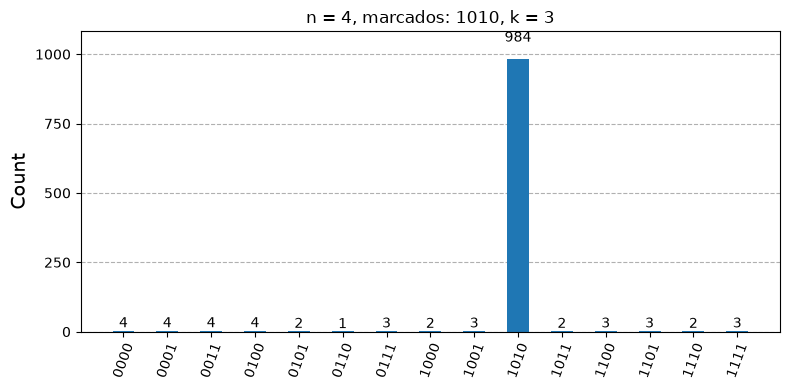

In [7]:
Experimento(4, '1010', 'n4')

## Caso $n = 5$

Experimento n5
Número de qubits:         n = 5
Espacio de búsqueda:      N = 2^n = 32
Estados marcados (M=1):   |10110>
Número de iteraciones:    k = floor(π/4·√(N/M)) = floor(4.443) = 4
Probabilidad de éxito:    teórica = 0.9992   medida = 1.0000 (1024/1024)
Cada estado no marcado:   0.000026

Distribución de probabilidades final (Statevector) y conteos medidos:
  |00000>  0.000026       0
  |00001>  0.000026       0
  |00010>  0.000026       0
  |00011>  0.000026       0
  |00100>  0.000026       0
  |00101>  0.000026       0
  |00110>  0.000026       0
  |00111>  0.000026       0
  |01000>  0.000026       0
  |01001>  0.000026       0
  |01010>  0.000026       0
  |01011>  0.000026       0
  |01100>  0.000026       0
  |01101>  0.000026       0
  |01110>  0.000026       0
  |01111>  0.000026       0
  |10000>  0.000026       0
  |10001>  0.000026       0
  |10010>  0.000026       0
  |10011>  0.000026       0
  |10100>  0.000026       0
  |10101>  0.000026       0
  |10110>  0.99918

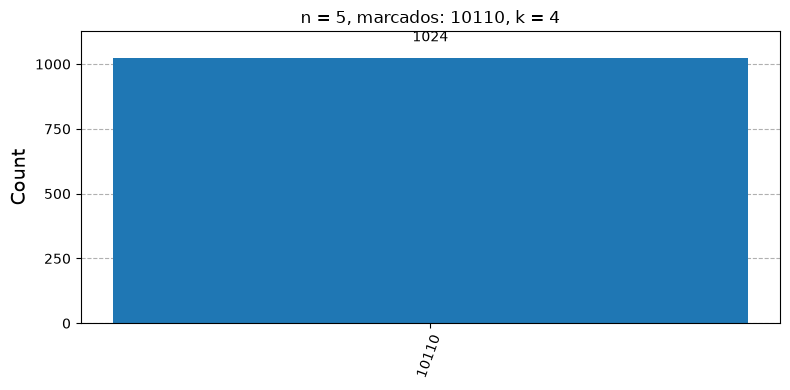

In [8]:
Experimento(5, '10110', 'n5')

## Caso $n = 6$

Experimento n6
Número de qubits:         n = 6
Espacio de búsqueda:      N = 2^n = 64
Estados marcados (M=1):   |110010>
Número de iteraciones:    k = floor(π/4·√(N/M)) = floor(6.283) = 6
Probabilidad de éxito:    teórica = 0.9966   medida = 0.9961 (1020/1024)
Cada estado no marcado:   0.000054

Distribución de probabilidades final (Statevector) y conteos medidos:
  |000000>  0.000054       0
  |000001>  0.000054       0
  |000010>  0.000054       0
  |000011>  0.000054       0
  |000100>  0.000054       0
  |000101>  0.000054       0
  |000110>  0.000054       0
  |000111>  0.000054       0
  |001000>  0.000054       0
  |001001>  0.000054       0
  |001010>  0.000054       1
  |001011>  0.000054       0
  |001100>  0.000054       0
  |001101>  0.000054       0
  |001110>  0.000054       0
  |001111>  0.000054       0
  |010000>  0.000054       0
  |010001>  0.000054       0
  |010010>  0.000054       0
  |010011>  0.000054       0
  |010100>  0.000054       0
  |010101>  0.000054    

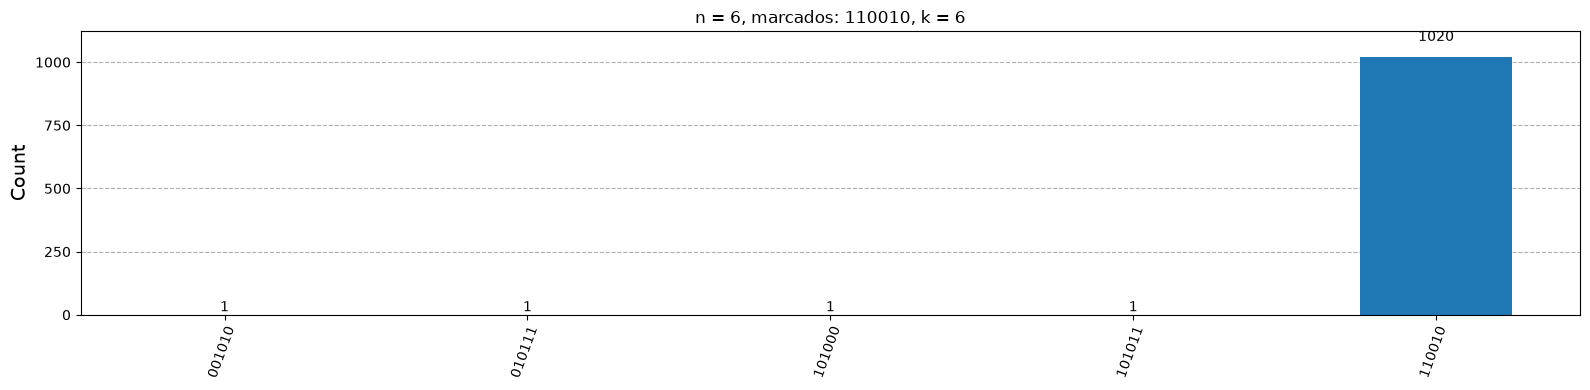

In [9]:
Experimento(6, '110010', 'n6')

## Caso adicional: $n = 5$ con dos estados marcados

Experimento n5_M2
Número de qubits:         n = 5
Espacio de búsqueda:      N = 2^n = 32
Estados marcados (M=2):   |00111>, |11001>
Número de iteraciones:    k = floor(π/4·√(N/M)) = floor(3.142) = 3
Probabilidad de éxito:    teórica = 0.9613   medida = 0.9580 (981/1024)
Cada estado no marcado:   0.001289

Distribución de probabilidades final (Statevector) y conteos medidos:
  |00000>  0.001289       2
  |00001>  0.001289       2
  |00010>  0.001289       1
  |00011>  0.001289       3
  |00100>  0.001289       0
  |00101>  0.001289       0
  |00110>  0.001289       1
  |00111>  0.480659     508  <- marcado
  |01000>  0.001289       0
  |01001>  0.001289       0
  |01010>  0.001289       0
  |01011>  0.001289       0
  |01100>  0.001289       3
  |01101>  0.001289       1
  |01110>  0.001289       2
  |01111>  0.001289       1
  |10000>  0.001289       2
  |10001>  0.001289       1
  |10010>  0.001289       1
  |10011>  0.001289       3
  |10100>  0.001289       2
  |10101>  0.001289    

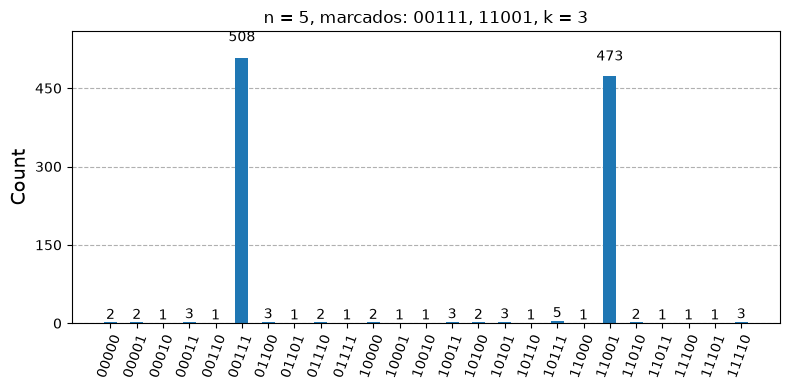

In [10]:
Experimento(5, ['00111', '11001'], 'n5_M2')

## Resumen

In [11]:
print(f"{'Experimento':>11} {'n':>2} {'N':>4} {'Marcados':>13} {'M':>2} {'k':>3} {'P éxito teórica':>16} {'P éxito medida':>15}")
for fila in resumen:
    et, n_, N_, marc, M_, k_, p_teo, p_med, _, _ = fila
    print(f"{et:>11} {n_:>2} {N_:>4} {marc:>13} {M_:>2} {k_:>3} {p_teo:>16.4f} {p_med:>15.4f}")

# Guardar resultados
with open('../resultados/experimentos_simulacion.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['experimento', 'n', 'N', 'estados_marcados', 'M', 'k', 'p_exito_teorica', 'p_exito_medida', 'conteos_marcados', 'disparos'])
    w.writerows(resumen)
with open('../resultados/distribuciones_simulacion.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['experimento', 'n', 'estado', 'marcado', 'probabilidad_statevector', 'conteos'])
    w.writerows(distribuciones)
print('\nGuardado en ../resultados/experimentos_simulacion.csv y ../resultados/distribuciones_simulacion.csv')

Experimento  n    N      Marcados  M   k  P éxito teórica  P éxito medida
         n4  4   16          1010  1   3           0.9613          0.9609
         n5  5   32         10110  1   4           0.9992          1.0000
         n6  6   64        110010  1   6           0.9966          0.9961
      n5_M2  5   32   00111 11001  2   3           0.9613          0.9580

Guardado en ../resultados/experimentos_simulacion.csv y ../resultados/distribuciones_simulacion.csv


## Interpretación de los resultados

| Experimento | $n$ | $N$ | Marcados | $k$ | $P$ éxito teórica | $P$ éxito medida | Cada no marcado |
|---|---|---|---|---|---|---|---|
| n4 | 4 | 16 | `1010` | 3 | 0.9613 | 0.9609 (984/1024) | 0.002579 |
| n5 | 5 | 32 | `10110` | 4 | 0.9992 | 1.0000 (1024/1024) | 0.000026 |
| n6 | 6 | 64 | `110010` | 6 | 0.9966 | 0.9961 (1020/1024) | 0.000054 |
| n5_M2 | 5 | 32 | `00111`, `11001` | 3 | 0.9613 | 0.9580 (981/1024) | 0.001289 |

- **$n = 4$.** Con $k = 3$ el estado $\lvert 1010\rangle$ queda con probabilidad 0.9613 y cada uno de los otros 15 estados con 0.0026. No llega a 1 porque
  $(2k+1)\theta = 7 \cdot 14.48^\circ = 101.4^\circ$ se pasa un poco de $90^\circ$.
- **$n = 5$.** $k = 4$ deja $(2k+1)\theta = 9 \cdot 10.18^\circ = 91.6^\circ$, muy cerca de $90^\circ$: la probabilidad es 0.9992 y los 1024 disparos dieron el estado marcado.
- **$n = 6$.** $k = 6$ deja $(2k+1)\theta = 13 \cdot 7.18^\circ = 93.4^\circ$ y la probabilidad es 0.9966.
- **$n = 5$ con dos estados marcados.** Con $M = 2$, $\sin\theta = \sqrt{2/32} = 1/4$, el mismo ángulo que $n = 4$ con un estado; por eso $k = 3$ y la probabilidad
  de éxito (suma de los dos estados marcados) es la misma, 0.9613. Los dos estados marcados quedan con la misma probabilidad cada uno (0.4806).
- **El número de iteraciones crece como $\sqrt N$:** $k = 3, 4, 6$ para $N = 16, 32, 64$. Una búsqueda clásica necesita en promedio del orden de $N/2$ consultas
  (8, 16 y 32), así que la ventaja cuadrática se nota más a medida que crece $n$.
- **La probabilidad no crece de forma monótona con $n$** ($n = 5$ supera a $n = 6$ y a $n = 4$): depende de qué tan cerca de $90^\circ$ quede $(2k+1)\theta$ con $k$ entero.
- **Teoría y medición coinciden** dentro de la variación estadística del muestreo: con $p \approx 0.96$ y 1024 disparos, la desviación estándar es
  $\sqrt{p(1-p)/1024} \approx 0.006$, y todas las diferencias son menores que eso.

In [12]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Python Version: 3.13.14
UdeA-Medellin (2026) ©
